# TACS (Ours) - Stanford Cars

Notebook này triển khai method hàng thứ 5 trong Table 2 của paper: **TACS (Ours)**.

Bản chất TACS: thay vì chọn context bằng random hoặc frozen DINO similarity cố định, notebook huấn luyện một **selector** để chọn context có ích cho downstream classifier. Selector nhận embedding của query và candidate, sinh utility score, chọn context bằng straight-through Gumbel-Softmax trong training và argmax trong inference.

Notebook giữ lại phần đã giúp bản tốt nhất của bạn đạt điểm cao: DINOv3 ViT-S/16, token-level query-context fusion, gated query/context head, strong augmentation, checkpoint sau từng epoch, TTA và cell in `test_accuracy`. Những phần không thuộc TACS như context-label prior được tắt.


In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# !unzip -q /content/drive/MyDrive/archive\ \(13\).zip -d /content/archive\ \(13\)/

## 1. Cài thư viện

Chạy cell này trên Colab nếu môi trường chưa có đủ thư viện. Nếu chạy local đã cài sẵn thì có thể bỏ qua.


In [3]:
%pip -q install torch torchvision pandas pillow tqdm matplotlib torchmetrics


Note: you may need to restart the kernel to use updated packages.


In [4]:
# !wget -c 'https://dinov3.llamameta.net/dinov3_vits16/dinov3_vits16_pretrain_lvd1689m-08c60483.pth?Policy=eyJTdGF0ZW1lbnQiOlt7InVuaXF1ZV9oYXNoIjoiNTFma3Jxa3l3bTl3MGpweHI2NndvNWZsIiwiUmVzb3VyY2UiOiJodHRwczpcL1wvZGlub3YzLmxsYW1hbWV0YS5uZXRcLyoiLCJDb25kaXRpb24iOnsiRGF0ZUxlc3NUaGFuIjp7IkFXUzpFcG9jaFRpbWUiOjE3ODkyOTc0MTJ9fX1dfQ__&Signature=sdowk%7EiiF6j8599sB9K5-M3sB%7Elq1be-oKP%7El7VBISEmjHEBPyCWw9Y2JD4oJY9LbXE313Q4ZgjX%7EXO3EiwGQZ3MZhfkZr0OXmADX8L%7E7XX%7E4mkVA1JSOkVzEa3Oj39gY%7E%7ER21%7EmJXEcFOZPMj%7EzGs-uxIh1xeRrfo-ZUqv3Yz7z7vUgn1OoDhu98kPnh8KT4MF1Gd6gcB4LogqWk3ooVScR6z8ECw50eawfY8lyUUzv%7E%7Em1QdstSU1k6HFhKFbuuogf0MyH7rzYScskxtGG95ke47CKn6CWSNbHLKhcLDfNx-XrN0A-xxis10rpJaMh2jBmxwohSr8XQlGVCBPWqQ__&Key-Pair-Id=K15QRJLYKIFSLZ&Download-Request-ID=1749739516259745' \
#   -O /content/dinov3_vits16_pretrain_lvd1689m-08c60483.pth

## 2. Import, cấu hình, dataset và candidate pool

Cell này đọc standard train/test split từ Stanford Cars. Theo paper, candidate pool lấy từ **20% train split**. Với TACS, candidate pool không được chọn bằng nhãn test; selector học utility score từ embedding query-candidate và được tối ưu bằng task loss + policy reward.


In [24]:
import json
import random
import subprocess
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm
torch.backends.cudnn.benchmark = True
# Tận dụng Tensor Cores thế hệ mới trên dòng RTX 6000:
torch.set_float32_matmul_precision('high')
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('DEVICE:', DEVICE)

from pathlib import Path

# --- ĐƯỜNG DẪN OUTPUT (Ghi vào working của Kaggle) ---
PROJECT_DIR = Path('/kaggle/working')
OUT_PUT_DIR = PROJECT_DIR / 'outputs' / 'baseline_tacs_cars'
OUTPUT_DIR = OUT_PUT_DIR
OUT_PUT_DIR.mkdir(parents=True, exist_ok=True)

# --- ĐƯỜNG DẪN DATASET (Stanford Cars) ---
DATASET_ROOT = Path(
    '/kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder'
)
TRAIN_IMAGE_ROOT = DATASET_ROOT / 'car_data' / 'car_data' / 'train'
TEST_IMAGE_ROOT = DATASET_ROOT / 'car_data' / 'car_data' / 'test'

# --- ĐƯỜNG DẪN DINOv3 REPO & WEIGHTS (Chỉ trỏ tới thư mục chứa hubconf.py) ---
DINOV3_REPO_DIR = (
    '/kaggle/input/datasets/sinhnguync/dinov3-code/dinov3-main'  # thư mục chứa hubconf.py
)
DINOV3_MODEL_NAME = 'dinov3_vits16'
DINOV3_WEIGHTS = '/kaggle/input/datasets/sinhnguync/dinov3/dinov3_vits16_pretrain_lvd1689m-08c60483.pth'

BACKBONE_NAME = DINOV3_MODEL_NAME
FEATURE_DIM = 384

IMAGE_SIZE = 448
BATCH_SIZE = 64
EPOCHS = 100
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4  # legacy default kept for older cells; optimizer below uses param groups
BACKBONE_LR = 3e-6
HEAD_LR = 1e-4
BACKBONE_WEIGHT_DECAY = 0.05
HEAD_WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1
TOKEN_HEAD_DROPOUT = 0.3
FREEZE_BACKBONE_EPOCHS = 5
WARMUP_EPOCHS = 5
PATIENCE = 10
GRAD_CLIP_NORM = 1.0
NUM_WORKERS = 8
NUM_CLASSES = 196
TOP_K = 5
CONTEXT_TOP_K = 1
RETRIEVAL_SCORE_WEIGHT = 0.0
SUPCON_WEIGHT = 0.05
SUPCON_TEMPERATURE = 0.10
USE_BBOX_CROP = True
CANDIDATE_POOL_FRACTION = 0.20
VAL_FRACTION = 0.10
RETRIEVAL_BATCH_SIZE = 512
RETRIEVAL_CHUNK_SIZE = 4096
QUERY_CONTEXT_GATE_DROPOUT = 0.20
QUERY_CONTEXT_GATE_BIAS = -0.7
EVAL_TTA_HORIZONTAL_FLIP = True
USE_CONTEXT_LABEL_PRIOR = False
CONTEXT_LABEL_PRIOR_WEIGHT = 0.25
CONTEXT_LABEL_PRIOR_TEMPERATURE = 0.07

TRAIN_ON_FULL_TRAIN = True
FULL_TRAIN_MONITOR_FRACTION = 0.05

# --- TACS selector hyperparameters ---
TACS_CANDIDATES_PER_QUERY = 4
TACS_PREFILTER_TOP_SIMILAR = 2  # shortlist speed-up: top-DINO candidates + random candidates
TACS_GUMBEL_TAU = 0.10
TACS_POLICY_WEIGHT = 1.0
TACS_ENTROPY_WEIGHT = 0.01
TACS_SELECTOR_LR = 1e-4
TACS_SELECTOR_WEIGHT_DECAY = 1e-4
TACS_SELECTOR_DROPOUT = 0.10
TACS_SELECTOR_TEMPERATURE = 1.0
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE + 48, IMAGE_SIZE + 48)),
    transforms.RandomResizedCrop(
        (IMAGE_SIZE, IMAGE_SIZE),
        scale=(0.60, 1.0),
        ratio=(0.80, 1.25),
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.25,
            contrast=0.25,
            saturation=0.20,
            hue=0.04,
        )
    ], p=0.75),
    transforms.RandomGrayscale(p=0.05),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
    ], p=0.15),
    transforms.ToTensor(),
    transforms.RandomErasing(
        p=0.20,
        scale=(0.02, 0.12),
        ratio=(0.3, 3.3),
        value="random",
    ),
    transforms.Normalize(imagenet_mean, imagenet_std),
])
# Deterministic transform for validation / test / candidate feature extraction
# Không dùng augmentation mạnh ở eval/retrieval để tránh retrieval bị nhiễu.

_mean = globals().get("DINO_MEAN", globals().get("IMAGENET_MEAN", (0.485, 0.456, 0.406)))
_std = globals().get("DINO_STD", globals().get("IMAGENET_STD", (0.229, 0.224, 0.225)))

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=_mean, std=_std),
])

def load_class_names(dataset_root):
    class_names = pd.read_csv(dataset_root / 'names.csv', header=None)[0].astype(str).tolist()
    if len(class_names) != NUM_CLASSES:
        raise ValueError(f'Expected {NUM_CLASSES} classes, got {len(class_names)}')
    return class_names


def load_annotations(dataset_root, split):
    df = pd.read_csv(
        dataset_root / f'anno_{split}.csv',
        header=None,
        names=['fname', 'bbox_x1', 'bbox_y1', 'bbox_x2', 'bbox_y2', 'class_id_1based'],
    )
    df['class_id'] = df['class_id_1based'].astype(int) - 1
    df['split'] = split
    df['row_id'] = np.arange(len(df))
    return df


def attach_image_paths(df, image_root):
    image_index = {path.name: path for path in sorted(Path(image_root).rglob('*.jpg'))}
    missing = [fname for fname in df['fname'] if fname not in image_index]
    if missing:
        raise FileNotFoundError(f'Thieu anh trong {image_root}, vi du: {missing[:5]}')
    out = df.copy()
    out['image_path'] = [str(image_index[fname]) for fname in out['fname']]
    return out


def split_train_val_by_class(df, val_fraction=0.10, seed=42):
    if not 0 < val_fraction < 1:
        raise ValueError('val_fraction phải nằm trong khoảng (0, 1)')
    rng = np.random.default_rng(seed)
    val_indices = []
    for _, group in df.groupby('class_id', sort=True):
        group_indices = group.index.to_numpy()
        if len(group_indices) <= 1:
            continue
        n_val = max(1, int(round(len(group_indices) * val_fraction)))
        n_val = min(n_val, len(group_indices) - 1)
        val_indices.extend(rng.choice(group_indices, size=n_val, replace=False).tolist())
    val_indices = np.array(sorted(val_indices), dtype=int)
    train_split = df.drop(index=val_indices).reset_index(drop=True)
    val_split = df.loc[val_indices].reset_index(drop=True)
    return train_split, val_split


class_names = load_class_names(DATASET_ROOT)
full_train_df = attach_image_paths(load_annotations(DATASET_ROOT, 'train'), TRAIN_IMAGE_ROOT).reset_index(drop=True)
test_df = attach_image_paths(load_annotations(DATASET_ROOT, 'test'), TEST_IMAGE_ROOT).reset_index(drop=True)
train_df, val_df = split_train_val_by_class(full_train_df, VAL_FRACTION, SEED)
NUM_CLASSES = len(class_names)
if TRAIN_ON_FULL_TRAIN:
    _, monitor_val_df = split_train_val_by_class(
        full_train_df,
        FULL_TRAIN_MONITOR_FRACTION,
        SEED
    )
    train_df = full_train_df.reset_index(drop=True)
    val_df = monitor_val_df.reset_index(drop=True)

candidate_rng = np.random.default_rng(SEED)
if CANDIDATE_POOL_FRACTION >= 1.0:
    candidate_pool_positions = np.arange(len(train_df), dtype=int)
else:
    candidate_pool_size = max(1, int(round(len(train_df) * CANDIDATE_POOL_FRACTION)))
    candidate_pool_positions = np.sort(candidate_rng.choice(len(train_df), size=candidate_pool_size, replace=False))
candidate_df = train_df.iloc[candidate_pool_positions].reset_index(drop=True)
candidate_df.to_csv(OUT_PUT_DIR / 'candidate_pool.csv', index=False)
val_df.to_csv(OUT_PUT_DIR / 'validation_split.csv', index=False)

print('DATASET_ROOT:', DATASET_ROOT.resolve())
print('TRAIN_IMAGE_ROOT:', TRAIN_IMAGE_ROOT.resolve())
print('TEST_IMAGE_ROOT:', TEST_IMAGE_ROOT.resolve())
print('OUT_PUT_DIR:', OUT_PUT_DIR.resolve())
print(f'Standard train images: {len(full_train_df):,}')
print(f'Actual train images: {len(train_df):,}')
print(f'Monitor validation images: {len(val_df):,}')
print(f'Train on full train: {TRAIN_ON_FULL_TRAIN}')
print(f'Standard test images: {len(test_df):,}')
print(f'Candidate pool: {len(candidate_df):,}/{len(train_df):,} actual-train images ({CANDIDATE_POOL_FRACTION:.0%})')
print(f'TACS selected context per query: {CONTEXT_TOP_K}')
print(f'TACS candidates per query during training: {TACS_CANDIDATES_PER_QUERY}')
print(f'TACS Gumbel tau: {TACS_GUMBEL_TAU}, policy weight: {TACS_POLICY_WEIGHT}')
print(f'BBox crop enabled: {USE_BBOX_CROP}')
print(f'Train label range: {int(train_df.class_id.min())}..{int(train_df.class_id.max())}')
print(f'Test label range: {int(test_df.class_id.min())}..{int(test_df.class_id.max())}')
display(train_df.head())
display(val_df.head())
display(candidate_df.head())


DEVICE: cuda
DATASET_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder
TRAIN_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/train
TEST_IMAGE_ROOT: /kaggle/input/datasets/jutrera/stanford-car-dataset-by-classes-folder/car_data/car_data/test
OUT_PUT_DIR: /kaggle/working/outputs/baseline_tacs_cars
Standard train images: 8,144
Actual train images: 8,144
Monitor validation images: 390
Train on full train: True
Standard test images: 8,041
Candidate pool: 1,629/8,144 actual-train images (20%)
TACS selected context per query: 1
TACS candidates per query during training: 4
TACS Gumbel tau: 0.1, policy weight: 1.0
BBox crop enabled: True
Train label range: 0..195
Test label range: 0..195


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00001.jpg,39,116,569,375,14,13,train,0,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00002.jpg,36,116,868,587,3,2,train,1,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00003.jpg,85,109,601,381,91,90,train,2,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00004.jpg,621,393,1484,1096,134,133,train,3,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00005.jpg,14,36,133,99,106,105,train,4,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00003.jpg,85,109,601,381,91,90,train,2,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00020.jpg,17,281,961,596,57,56,train,19,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00063.jpg,175,330,928,647,101,100,train,62,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00079.jpg,165,126,749,425,133,132,train,78,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00092.jpg,101,84,492,272,138,137,train,91,/kaggle/input/datasets/jutrera/stanford-car-da...


,fname,bbox_x1,bbox_y1,bbox_x2,bbox_y2,class_id_1based,class_id,split,row_id,image_path
0,00010.jpg,21,110,623,367,58,57,train,9,/kaggle/input/datasets/jutrera/stanford-car-da...
1,00013.jpg,30,36,418,307,135,134,train,12,/kaggle/input/datasets/jutrera/stanford-car-da...
2,00014.jpg,31,246,778,540,85,84,train,13,/kaggle/input/datasets/jutrera/stanford-car-da...
3,00033.jpg,34,197,1011,656,66,65,train,32,/kaggle/input/datasets/jutrera/stanford-car-da...
4,00036.jpg,138,41,521,223,104,103,train,35,/kaggle/input/datasets/jutrera/stanford-car-da...


## 3. Dataset pair và DataLoader

TACS cần dataset khác baseline tĩnh: mỗi query nhận một shortlist candidate để selector học chọn. Notebook vẫn giữ dataset pair cố định để dùng cho final test sau khi selector đã chọn context tốt nhất từ full candidate pool.


In [25]:
class SimpleImageDataset(Dataset):
    def __init__(self, annotations, transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.transform = transform
        self.crop_bbox = crop_bbox

    def __len__(self):
        return len(self.annotations)

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        image = self.transform(self._open_image(row))
        return image, int(index), row['fname'], int(row['class_id'])


class StanfordCarsSimilarityContextDataset(Dataset):
    def __init__(self, annotations, candidate_annotations, context_positions, context_scores, query_transform, context_transform, crop_bbox=False):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.candidate_annotations = candidate_annotations.reset_index(drop=True).copy()
        self.context_positions = np.asarray(context_positions, dtype=np.int64)
        self.context_scores = np.asarray(context_scores, dtype=np.float32)
        if self.context_positions.ndim == 1:
            self.context_positions = self.context_positions[:, None]
        if self.context_scores.ndim == 1:
            self.context_scores = self.context_scores[:, None]
        self.query_transform = query_transform
        self.context_transform = context_transform
        self.crop_bbox = crop_bbox
        if len(self.context_positions) != len(self.annotations):
            raise ValueError('context_positions phai co cung do dai voi annotations')
        if len(self.context_scores) != len(self.annotations):
            raise ValueError('context_scores phai co cung do dai voi annotations')

    def __len__(self):
        return len(self.annotations)

    def set_epoch(self, epoch):
        pass

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        query_row = self.annotations.iloc[index]
        context_positions = self.context_positions[index]
        context_scores = self.context_scores[index]
        context_rows = [self.candidate_annotations.iloc[int(pos)] for pos in context_positions]
        query_image = self.query_transform(self._open_image(query_row))
        context_images = torch.stack([self.context_transform(self._open_image(context_row)) for context_row in context_rows], dim=0)
        context_labels = torch.tensor([int(context_row['class_id']) for context_row in context_rows], dtype=torch.long)
        return {
            'query_image': query_image,
            'context_images': context_images,
            'label': torch.tensor(int(query_row['class_id']), dtype=torch.long),
            'fname': query_row['fname'],
            'context_fnames': '|'.join(str(context_row['fname']) for context_row in context_rows),
            "context_labels": torch.tensor(context_labels, dtype=torch.long),
            'context_scores': torch.as_tensor(context_scores, dtype=torch.float32),
        }


class StanfordCarsTACSCandidateDataset(Dataset):
    def __init__(
        self,
        annotations,
        candidate_annotations,
        candidate_subset_positions,
        query_selector_embeddings,
        candidate_selector_embeddings,
        query_transform,
        candidate_transform,
        crop_bbox=False,
    ):
        self.annotations = annotations.reset_index(drop=True).copy()
        self.candidate_annotations = candidate_annotations.reset_index(drop=True).copy()
        self.candidate_subset_positions = np.asarray(candidate_subset_positions, dtype=np.int64)
        self.query_selector_embeddings = torch.as_tensor(query_selector_embeddings, dtype=torch.float32)
        self.candidate_selector_embeddings = torch.as_tensor(candidate_selector_embeddings, dtype=torch.float32)
        self.query_transform = query_transform
        self.candidate_transform = candidate_transform
        self.crop_bbox = crop_bbox
        if len(self.candidate_subset_positions) != len(self.annotations):
            raise ValueError('candidate_subset_positions phai co cung do dai voi annotations')

    def __len__(self):
        return len(self.annotations)

    def _open_image(self, row):
        image = Image.open(row['image_path']).convert('RGB')
        if self.crop_bbox:
            left = max(0, int(row['bbox_x1']) - 1)
            top = max(0, int(row['bbox_y1']) - 1)
            right = min(image.width, max(left + 1, int(row['bbox_x2'])))
            bottom = min(image.height, max(top + 1, int(row['bbox_y2'])))
            image = image.crop((left, top, right, bottom))
        return image

    def __getitem__(self, index):
        row = self.annotations.iloc[index]
        candidate_positions = self.candidate_subset_positions[index]
        candidate_rows = [self.candidate_annotations.iloc[int(pos)] for pos in candidate_positions]

        query_image = self.query_transform(self._open_image(row))
        candidate_images = torch.stack(
            [self.candidate_transform(self._open_image(candidate_row)) for candidate_row in candidate_rows],
            dim=0,
        )
        candidate_labels = torch.tensor([int(candidate_row['class_id']) for candidate_row in candidate_rows], dtype=torch.long)
        candidate_embeddings = self.candidate_selector_embeddings[torch.as_tensor(candidate_positions, dtype=torch.long)]

        return {
            'query_image': query_image,
            'candidate_images': candidate_images,
            'query_selector_embedding': self.query_selector_embeddings[index],
            'candidate_selector_embeddings': candidate_embeddings,
            'candidate_labels': candidate_labels,
            'candidate_positions': torch.as_tensor(candidate_positions, dtype=torch.long),
            'label': torch.tensor(int(row['class_id']), dtype=torch.long),
            'fname': row['fname'],
            'context_fnames': '|'.join(str(candidate_row['fname']) for candidate_row in candidate_rows),
            'context_scores': torch.zeros(len(candidate_positions), dtype=torch.float32),
        }



## 4. TACS selector và downstream model

Selector: dùng embedding DINOv3 frozen làm quan sát ban đầu cho query/candidate, sau đó học projection để utility score phản ánh **task usefulness** thay vì chỉ visual similarity. Trong training, selector chọn context bằng straight-through Gumbel-Softmax. Policy path dùng reward `loss_query_only - loss_with_context`.

Downstream classifier: giữ kiến trúc mạnh từ notebook tốt nhất: DINOv3 ViT-S/16, token-level query-context fusion và gated query/context head. Khi test, selector được dùng để chọn context tốt nhất từ toàn bộ candidate pool 20%.


In [26]:
from pathlib import Path
import gc
import torch


def resolve_dinov3_weights():
    path = Path(DINOV3_WEIGHTS)
    if not path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {path}')
    return str(path)


def load_dinov3_model(repo_dir, model_name, weights_path):
    repo_dir = Path(repo_dir)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    weights_path = Path(weights_path)
    if not weights_path.is_file():
        raise FileNotFoundError(f'Không tìm thấy file weight: {weights_path}')
    return torch.hub.load(str(repo_dir), model_name, source='local', weights=str(weights_path))


def load_dinov3_backbone():
    return load_dinov3_model(DINOV3_REPO_DIR, DINOV3_MODEL_NAME, resolve_dinov3_weights())


def ensure_dinov3_assets():
    resolve_dinov3_weights()
    repo_dir = Path(DINOV3_REPO_DIR)
    if not repo_dir.is_dir():
        raise FileNotFoundError(f'Không tìm thấy thư mục mã nguồn: {repo_dir}')
    print('DINOv3 assets đã sẵn sàng từ Kaggle Input.')


def extract_cls_features(backbone, images):
    features = backbone(images)
    if isinstance(features, dict):
        if 'x_norm_clstoken' in features:
            return features['x_norm_clstoken']
        if 'x_norm_cls_token' in features:
            return features['x_norm_cls_token']
        if 'x_norm_patchtokens' in features:
            return features['x_norm_patchtokens'].mean(dim=1)
        raise KeyError(f'Khong tim thay CLS token trong output keys: {list(features)}')
    return features[:, 0] if torch.is_tensor(features) and features.ndim == 3 else features


def extract_frozen_dino_embeddings(annotations, backbone, desc):
    dataset = SimpleImageDataset(annotations, eval_transform, crop_bbox=USE_BBOX_CROP)
    loader = DataLoader(dataset, batch_size=RETRIEVAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True,persistent_workers=True if NUM_WORKERS > 0 else False)
    embeddings = []
    backbone.eval()
    for parameter in backbone.parameters():
        parameter.requires_grad_(False)
    with torch.inference_mode():
        for images, *_ in tqdm(loader, desc=desc, leave=False):
            images = images.to(DEVICE, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
                features = extract_cls_features(backbone, images)
            features = F.normalize(features.float(), dim=1)
            embeddings.append(features.cpu())
    return torch.cat(embeddings, dim=0)




class DinoV3FrozenSimilarityContextClassifier(nn.Module):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=384, allow_feature_fallback=False):
        super().__init__()
        self.backbone = load_dinov3_model(repo_dir, model_name, weights_path)
        self.feature_dim = feature_dim
        self.allow_feature_fallback = allow_feature_fallback
        self.active_fusion_mode = 'topk_token_attention'
        self.context_proj = nn.Linear(feature_dim, feature_dim)
        self.query_proj = nn.Linear(feature_dim, feature_dim)
        self.context_attention = nn.Linear(feature_dim, 1)
        self.fusion_norm = nn.LayerNorm(feature_dim)
        self.token_head = nn.Sequential(nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        self.feature_fusion = nn.Sequential(nn.Linear(feature_dim * 2, feature_dim), nn.GELU(), nn.Dropout(p=TOKEN_HEAD_DROPOUT), nn.Linear(feature_dim, num_classes))
        for param in self.backbone.parameters():
            param.requires_grad_(False)

    def _prefix_token_count(self):
        if hasattr(self.backbone, 'num_prefix_tokens'):
            return int(self.backbone.num_prefix_tokens)
        storage_tokens = getattr(self.backbone, 'n_storage_tokens', None)
        if storage_tokens is None:
            storage_tokens = getattr(self.backbone, 'num_register_tokens', 0)
        return 1 + int(storage_tokens or 0)

    def _patch_grid(self, images):
        patch_size = getattr(self.backbone, 'patch_size', 16)
        if isinstance(patch_size, (tuple, list)):
            patch_h, patch_w = int(patch_size[0]), int(patch_size[1])
        else:
            patch_h = patch_w = int(patch_size)
        return images.shape[-2] // patch_h, images.shape[-1] // patch_w

    def _unwrap_tokens(self, prepared):
        if torch.is_tensor(prepared):
            return prepared
        if isinstance(prepared, (tuple, list)):
            for item in prepared:
                if torch.is_tensor(item):
                    return item
        if isinstance(prepared, dict):
            for key in ('x', 'tokens', 'last_hidden_state'):
                if key in prepared and torch.is_tensor(prepared[key]):
                    return prepared[key]
            for item in prepared.values():
                if torch.is_tensor(item):
                    return item
        raise TypeError(f'Cannot unwrap DINO token output of type {type(prepared)}')

    def _prepare_tokens_with_rope(self, images):
        try:
            prepared = self.backbone.prepare_tokens_with_masks(images, None)
        except TypeError:
            prepared = self.backbone.prepare_tokens_with_masks(images)
        tokens = self._unwrap_tokens(prepared)
        rope = None
        if hasattr(self.backbone, 'rope_embed'):
            grid_h, grid_w = self._patch_grid(images)
            try:
                rope = self.backbone.rope_embed(H=grid_h, W=grid_w)
            except TypeError:
                rope = self.backbone.rope_embed(grid_h, grid_w)
        return tokens, rope

    def _repeat_rope_for_query_context(self, rope):
        if rope is None or not torch.is_tensor(rope):
            return rope
        try:
            return rope.repeat_interleave(2, dim=-2)
        except RuntimeError:
            return rope

    def _run_blocks(self, tokens, rope):
        for block in self.backbone.blocks:
            if rope is None:
                tokens = block(tokens)
                continue
            try:
                tokens = block(tokens, rope=rope)
            except TypeError:
                try:
                    tokens = block(tokens, rope)
                except TypeError:
                    tokens = block(tokens)
        if hasattr(self.backbone, 'norm'):
            tokens = self.backbone.norm(tokens)
        return tokens

    def _forward_token_concat_features(self, query_images, context_images):
        query_tokens, query_rope = self._prepare_tokens_with_rope(query_images)
        context_tokens, _ = self._prepare_tokens_with_rope(context_images)
        prefix_tokens = self._prefix_token_count()
        pair_tokens = torch.cat([query_tokens[:, :prefix_tokens], query_tokens[:, prefix_tokens:], context_tokens[:, prefix_tokens:]], dim=1)
        pair_rope = self._repeat_rope_for_query_context(query_rope)
        pair_tokens = self._run_blocks(pair_tokens, pair_rope)
        return pair_tokens[:, 0]

    def _pool_backbone_features(self, images):
        features = self.backbone.forward_features(images)
        if isinstance(features, dict):
            if 'x_norm_clstoken' in features:
                return features['x_norm_clstoken']
            if 'x_norm_patchtokens' in features:
                return features['x_norm_patchtokens'].mean(dim=1)
            for item in features.values():
                if torch.is_tensor(item):
                    return item[:, 0] if item.ndim == 3 else item
        if torch.is_tensor(features):
            return features[:, 0] if features.ndim == 3 else features
        raise TypeError(f'Cannot pool DINO features of type {type(features)}')

    def _forward_feature_fusion(self, query_images, context_images):
        if context_images.ndim == 5:
            context_images = context_images[:, 0]
        query_features = self._pool_backbone_features(query_images)
        context_features = self._pool_backbone_features(context_images)
        self.active_fusion_mode = 'feature_fusion'
        return self.feature_fusion(torch.cat([query_features, context_features], dim=1))

    def _forward_topk_token_attention(self, query_images, context_images, context_scores=None):
        if context_images.ndim == 4:
            context_images = context_images.unsqueeze(1)
        batch_size, num_contexts, channels, height, width = context_images.shape
        query_repeated = query_images.unsqueeze(1).expand(-1, num_contexts, -1, -1, -1).reshape(batch_size * num_contexts, channels, height, width)
        context_flat = context_images.reshape(batch_size * num_contexts, channels, height, width)
        pair_features = self._forward_token_concat_features(query_repeated, context_flat).reshape(batch_size, num_contexts, self.feature_dim)
        query_summary = pair_features.mean(dim=1)
        attention_hidden = torch.tanh(self.context_proj(pair_features) + self.query_proj(query_summary).unsqueeze(1))
        attention_logits = self.context_attention(attention_hidden).squeeze(-1)
        if context_scores is not None:
            if context_scores.ndim == 1:
                context_scores = context_scores.unsqueeze(1)
            attention_logits = attention_logits + RETRIEVAL_SCORE_WEIGHT * context_scores.to(attention_logits.device, dtype=attention_logits.dtype)
        attention_weights = torch.softmax(attention_logits, dim=1)
        fused_features = torch.sum(pair_features * attention_weights.unsqueeze(-1), dim=1)
        fused_features = self.fusion_norm(fused_features)
        self.active_fusion_mode = 'topk_token_attention'
        return fused_features, attention_weights

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            fused_features, attention_weights = self._forward_topk_token_attention(query_images, context_images, context_scores=context_scores)
            logits = self.token_head(fused_features)
            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits
        except Exception as exc:
            if self.allow_feature_fallback:
                print(f'Top-k token attention failed, fallback to feature fusion: {type(exc).__name__}: {exc}')
                logits = self._forward_feature_fusion(query_images, context_images)
                if return_features:
                    return logits, F.normalize(logits.float(), dim=1), None
                return logits
            raise RuntimeError('Top-k token attention failed. Keep allow_feature_fallback=False for debugging.') from exc

class DinoV3GatedTopKContextClassifier(DinoV3FrozenSimilarityContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=384, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.query_norm = nn.LayerNorm(feature_dim)
        self.context_norm = nn.LayerNorm(feature_dim)
        self.final_norm = nn.LayerNorm(feature_dim)

        self.query_head = nn.Sequential(
            nn.Dropout(p=TOKEN_HEAD_DROPOUT),
            nn.Linear(feature_dim, num_classes),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(feature_dim * 4, feature_dim),
            nn.GELU(),
            nn.Dropout(p=QUERY_CONTEXT_GATE_DROPOUT),
            nn.Linear(feature_dim, 1),
        )
        nn.init.constant_(self.fusion_gate[-1].bias, QUERY_CONTEXT_GATE_BIAS)
        self.active_fusion_mode = "query_plus_gated_topk_context"

    def forward(self, query_images, context_images, context_scores=None, return_features=False):
        try:
            context_features, attention_weights = self._forward_topk_token_attention(
                query_images,
                context_images,
                context_scores=context_scores,
            )
            query_features = self._pool_backbone_features(query_images)

            query_features = self.query_norm(query_features)
            context_features = self.context_norm(context_features)

            gate_input = torch.cat(
                [
                    query_features,
                    context_features,
                    query_features * context_features,
                    torch.abs(query_features - context_features),
                ],
                dim=1,
            )
            gate = torch.sigmoid(self.fusion_gate(gate_input))

            query_logits = self.query_head(query_features)
            context_logits = self.token_head(context_features)
            logits = query_logits + gate * context_logits

            fused_features = self.final_norm(query_features + gate * context_features)
            self.active_fusion_mode = "query_plus_gated_topk_context"

            if return_features:
                return logits, F.normalize(fused_features.float(), dim=1), attention_weights
            return logits

        except Exception as exc:
            if self.allow_feature_fallback:
                print(f"Gated fusion failed, fallback to parent model: {type(exc).__name__}: {exc}")
                return super().forward(query_images, context_images, context_scores=context_scores, return_features=return_features)
            raise


class TACSSelector(nn.Module):
    def __init__(self, feature_dim=384, hidden_dim=384, dropout=0.10, temperature=1.0):
        super().__init__()
        self.temperature = float(temperature)
        self.query_proj = nn.Sequential(
            nn.LayerNorm(feature_dim),
            nn.Linear(feature_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, feature_dim),
        )
        self.candidate_proj = nn.Sequential(
            nn.LayerNorm(feature_dim),
            nn.Linear(feature_dim, hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, feature_dim),
        )

    def forward(self, query_embeddings, candidate_embeddings):
        query = F.normalize(self.query_proj(query_embeddings.float()), dim=-1)
        candidates = F.normalize(self.candidate_proj(candidate_embeddings.float()), dim=-1)
        scores = torch.einsum('bd,bkd->bk', query, candidates)
        return scores / max(self.temperature, 1e-6)

    @torch.no_grad()
    def score_full_pool(self, query_embeddings, candidate_embeddings, chunk_size=512, device=DEVICE):
        self.eval()
        candidate_embeddings = candidate_embeddings.to(device, non_blocking=True).float()
        candidate_proj = F.normalize(self.candidate_proj(candidate_embeddings), dim=-1)
        all_scores = []
        for start in tqdm(range(0, len(query_embeddings), chunk_size), desc='TACS full-pool selector', leave=False):
            end = min(start + chunk_size, len(query_embeddings))
            query_chunk = query_embeddings[start:end].to(device, non_blocking=True).float()
            query_proj = F.normalize(self.query_proj(query_chunk), dim=-1)
            scores = query_proj @ candidate_proj.T
            scores = scores / max(self.temperature, 1e-6)
            all_scores.append(scores.cpu())
        return torch.cat(all_scores, dim=0)


class DinoV3TACSClassifier(DinoV3GatedTopKContextClassifier):
    def __init__(self, repo_dir, model_name, weights_path, num_classes, feature_dim=384, allow_feature_fallback=False):
        super().__init__(
            repo_dir=repo_dir,
            model_name=model_name,
            weights_path=weights_path,
            num_classes=num_classes,
            feature_dim=feature_dim,
            allow_feature_fallback=allow_feature_fallback,
        )
        self.selector = TACSSelector(
            feature_dim=feature_dim,
            hidden_dim=feature_dim,
            dropout=TACS_SELECTOR_DROPOUT,
            temperature=TACS_SELECTOR_TEMPERATURE,
        )
        self.active_fusion_mode = 'tacs_gumbel_selector'

    def select_context(self, query_selector_embeddings, candidate_selector_embeddings, candidate_images, use_gumbel=True):
        selector_scores = self.selector(query_selector_embeddings, candidate_selector_embeddings)
        if self.training and use_gumbel:
            selection_weights = F.gumbel_softmax(
                selector_scores,
                tau=TACS_GUMBEL_TAU,
                hard=True,
                dim=1,
            )
        else:
            selected_indices = selector_scores.argmax(dim=1)
            selection_weights = F.one_hot(selected_indices, num_classes=selector_scores.size(1)).to(selector_scores.dtype)
        selected_images = torch.sum(
            candidate_images * selection_weights[:, :, None, None, None].to(candidate_images.dtype),
            dim=1,
        )
        selected_indices = selection_weights.argmax(dim=1)
        return selected_images, selector_scores, selection_weights, selected_indices

    def forward_selected_context(self, query_images, selected_context_images, return_features=False):
        context_images = selected_context_images.unsqueeze(1)
        return super().forward(query_images, context_images, context_scores=None, return_features=return_features)

    def forward_query_only(self, query_images):
        query_features = self._pool_backbone_features(query_images)
        if hasattr(self, 'query_norm') and hasattr(self, 'query_head'):
            query_features = self.query_norm(query_features)
            return self.query_head(query_features)
        return self.token_head(query_features)

    def forward_tacs(
        self,
        query_images,
        candidate_images,
        query_selector_embeddings,
        candidate_selector_embeddings,
        return_features=False,
        use_gumbel=True,
    ):
        selected_images, selector_scores, selection_weights, selected_indices = self.select_context(
            query_selector_embeddings,
            candidate_selector_embeddings,
            candidate_images,
            use_gumbel=use_gumbel,
        )
        output = self.forward_selected_context(query_images, selected_images, return_features=return_features)
        details = {
            'selector_scores': selector_scores,
            'selection_weights': selection_weights,
            'selected_indices': selected_indices,
            'selected_images': selected_images,
            'selector_entropy': torch.distributions.Categorical(logits=selector_scores.float()).entropy().mean(),
        }
        self.active_fusion_mode = 'tacs_gumbel_selector'
        if return_features:
            logits, features, attention = output
            return logits, features, attention, details
        return output, details


def build_tacs_candidate_subsets(
    query_embeddings,
    candidate_embeddings,
    query_df,
    candidate_df,
    num_candidates=4,
    num_similar=2,
    seed=SEED,
    exclude_self=False,
    chunk_size=1024,
):
    rng = np.random.default_rng(seed)
    num_candidates = int(max(1, min(num_candidates, len(candidate_df))))
    num_similar = int(max(0, min(num_similar, num_candidates)))
    num_random = num_candidates - num_similar
    all_positions = np.arange(len(candidate_df), dtype=np.int64)
    subsets = np.empty((len(query_df), num_candidates), dtype=np.int64)
    candidate_row_id_to_position = {int(row_id): pos for pos, row_id in enumerate(candidate_df['row_id'].tolist())}

    top_similar = np.empty((len(query_df), num_similar), dtype=np.int64) if num_similar > 0 else None
    if num_similar > 0:
        candidate_embeddings = candidate_embeddings.float()
        for start in tqdm(range(0, len(query_embeddings), chunk_size), desc='TACS shortlist similar candidates', leave=False):
            end = min(start + chunk_size, len(query_embeddings))
            similarities = query_embeddings[start:end].float() @ candidate_embeddings.T
            if exclude_self:
                for local_index, query_index in enumerate(range(start, end)):
                    query_row_id = int(query_df.iloc[query_index]['row_id'])
                    context_pos = candidate_row_id_to_position.get(query_row_id)
                    if context_pos is not None and len(candidate_df) > 1:
                        similarities[local_index, context_pos] = -float('inf')
            _, positions = torch.topk(similarities, k=num_similar, dim=1)
            top_similar[start:end] = positions.cpu().numpy()

    for query_index in range(len(query_df)):
        selected = []
        if num_similar > 0:
            selected.extend(int(pos) for pos in top_similar[query_index].tolist())
        valid_positions = all_positions
        if exclude_self:
            query_row_id = int(query_df.iloc[query_index]['row_id'])
            self_position = candidate_row_id_to_position.get(query_row_id)
            if self_position is not None and len(all_positions) > 1:
                valid_positions = all_positions[all_positions != self_position]
        if selected:
            valid_positions = np.array([pos for pos in valid_positions if int(pos) not in set(selected)], dtype=np.int64)
        replace = len(valid_positions) < num_random
        if num_random > 0:
            random_positions = rng.choice(valid_positions, size=num_random, replace=replace)
            selected.extend(int(pos) for pos in np.asarray(random_positions).tolist())
        if len(selected) < num_candidates:
            fill = rng.choice(all_positions, size=num_candidates - len(selected), replace=True)
            selected.extend(int(pos) for pos in np.asarray(fill).tolist())
        subsets[query_index] = np.array(selected[:num_candidates], dtype=np.int64)
    return subsets


def build_tacs_subset_summary_df(query_df, candidate_df, subset_positions):
    rows = []
    for query_index, positions in enumerate(subset_positions):
        query = query_df.iloc[query_index]
        context_rows = [candidate_df.iloc[int(pos)] for pos in positions]
        context_class_ids = [int(row['class_id']) for row in context_rows]
        query_class_id = int(query['class_id'])
        rows.append({
            'query_fname': query['fname'],
            'query_class_id': query_class_id,
            'query_car_name': class_names[query_class_id],
            'candidate_fnames': '|'.join(str(row['fname']) for row in context_rows),
            'candidate_class_ids': '|'.join(str(x) for x in context_class_ids),
            'candidate_pool_positions': '|'.join(str(int(pos)) for pos in positions),
            'contains_same_class': bool(query_class_id in context_class_ids),
            'top1_same_class': bool(query_class_id == context_class_ids[0]),
        })
    return pd.DataFrame(rows)


ensure_dinov3_assets()
selector_feature_backbone = load_dinov3_backbone().to(DEVICE).eval()
candidate_selector_embeddings = extract_frozen_dino_embeddings(candidate_df, selector_feature_backbone, 'candidate selector embeddings')
train_query_selector_embeddings = extract_frozen_dino_embeddings(train_df, selector_feature_backbone, 'train query selector embeddings')
val_query_selector_embeddings = extract_frozen_dino_embeddings(val_df, selector_feature_backbone, 'val query selector embeddings')
test_query_selector_embeddings = extract_frozen_dino_embeddings(test_df, selector_feature_backbone, 'test query selector embeddings')
del selector_feature_backbone
gc.collect()
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()

train_candidate_subset_positions = build_tacs_candidate_subsets(
    train_query_selector_embeddings,
    candidate_selector_embeddings,
    train_df,
    candidate_df,
    num_candidates=TACS_CANDIDATES_PER_QUERY,
    num_similar=TACS_PREFILTER_TOP_SIMILAR,
    seed=SEED + 101,
    exclude_self=True,
    chunk_size=RETRIEVAL_CHUNK_SIZE,
)
val_candidate_subset_positions = build_tacs_candidate_subsets(
    val_query_selector_embeddings,
    candidate_selector_embeddings,
    val_df,
    candidate_df,
    num_candidates=TACS_CANDIDATES_PER_QUERY,
    num_similar=TACS_PREFILTER_TOP_SIMILAR,
    seed=SEED + 202,
    exclude_self=False,
    chunk_size=RETRIEVAL_CHUNK_SIZE,
)
test_candidate_subset_positions = build_tacs_candidate_subsets(
    test_query_selector_embeddings,
    candidate_selector_embeddings,
    test_df,
    candidate_df,
    num_candidates=TACS_CANDIDATES_PER_QUERY,
    num_similar=TACS_PREFILTER_TOP_SIMILAR,
    seed=SEED + 303,
    exclude_self=False,
    chunk_size=RETRIEVAL_CHUNK_SIZE,
)

train_tacs_subset_df = build_tacs_subset_summary_df(train_df, candidate_df, train_candidate_subset_positions)
val_tacs_subset_df = build_tacs_subset_summary_df(val_df, candidate_df, val_candidate_subset_positions)
test_tacs_subset_df = build_tacs_subset_summary_df(test_df, candidate_df, test_candidate_subset_positions)
train_tacs_subset_df.to_csv(OUT_PUT_DIR / 'train_tacs_candidate_subsets.csv', index=False)
val_tacs_subset_df.to_csv(OUT_PUT_DIR / 'val_tacs_candidate_subsets.csv', index=False)
test_tacs_subset_df.to_csv(OUT_PUT_DIR / 'test_tacs_candidate_subsets.csv', index=False)

train_subset_same_class_rate = float(train_tacs_subset_df['contains_same_class'].mean())
val_subset_same_class_rate = float(val_tacs_subset_df['contains_same_class'].mean())
test_subset_same_class_rate = float(test_tacs_subset_df['contains_same_class'].mean())

torch.save({
    'candidate_selector_embeddings': candidate_selector_embeddings,
    'train_query_selector_embeddings': train_query_selector_embeddings,
    'val_query_selector_embeddings': val_query_selector_embeddings,
    'test_query_selector_embeddings': test_query_selector_embeddings,
    'candidate_pool_positions': torch.as_tensor(candidate_pool_positions, dtype=torch.long),
    'train_candidate_subset_positions': torch.as_tensor(train_candidate_subset_positions, dtype=torch.long),
    'val_candidate_subset_positions': torch.as_tensor(val_candidate_subset_positions, dtype=torch.long),
    'test_candidate_subset_positions': torch.as_tensor(test_candidate_subset_positions, dtype=torch.long),
    'seed': SEED,
    'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
    'tacs_candidates_per_query': TACS_CANDIDATES_PER_QUERY,
    'tacs_prefilter_top_similar': TACS_PREFILTER_TOP_SIMILAR,
    'use_bbox_crop': USE_BBOX_CROP,
}, OUT_PUT_DIR / 'tacs_selector_cache.pt')

train_dataset = StanfordCarsTACSCandidateDataset(
    train_df,
    candidate_df,
    train_candidate_subset_positions,
    train_query_selector_embeddings,
    candidate_selector_embeddings,
    train_transform,
    train_transform,
    crop_bbox=USE_BBOX_CROP,
)
val_dataset = StanfordCarsTACSCandidateDataset(
    val_df,
    candidate_df,
    val_candidate_subset_positions,
    val_query_selector_embeddings,
    candidate_selector_embeddings,
    eval_transform,
    eval_transform,
    crop_bbox=USE_BBOX_CROP,
)
test_dataset = StanfordCarsTACSCandidateDataset(
    test_df,
    candidate_df,
    test_candidate_subset_positions,
    test_query_selector_embeddings,
    candidate_selector_embeddings,
    eval_transform,
    eval_transform,
    crop_bbox=USE_BBOX_CROP,
)

loader_kwargs = {'num_workers': NUM_WORKERS, 'pin_memory': torch.cuda.is_available()}
if NUM_WORKERS > 0:
    loader_kwargs['persistent_workers'] = True
    loader_kwargs['prefetch_factor'] = 2

train_generator = torch.Generator()
train_generator.manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=train_generator, **loader_kwargs)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)

model = DinoV3TACSClassifier(
    DINOV3_REPO_DIR,
    DINOV3_MODEL_NAME,
    resolve_dinov3_weights(),
    NUM_CLASSES,
    FEATURE_DIM,
    allow_feature_fallback=False,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
backbone_params = [p for name, p in model.named_parameters() if name.startswith('backbone.')]
selector_params = [p for name, p in model.named_parameters() if name.startswith('selector.')]
head_params = [p for name, p in model.named_parameters() if not name.startswith('backbone.') and not name.startswith('selector.')]
optimizer = torch.optim.AdamW([
    {'params': backbone_params, 'lr': BACKBONE_LR, 'weight_decay': BACKBONE_WEIGHT_DECAY, 'name': 'backbone'},
    {'params': selector_params, 'lr': TACS_SELECTOR_LR, 'weight_decay': TACS_SELECTOR_WEIGHT_DECAY, 'name': 'selector'},
    {'params': head_params, 'lr': HEAD_LR, 'weight_decay': HEAD_WEIGHT_DECAY, 'name': 'head'},
])

warmup_epochs = max(1, min(WARMUP_EPOCHS, EPOCHS))
main_epochs = max(1, EPOCHS - warmup_epochs)
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.2, end_factor=1.0, total_iters=warmup_epochs)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=main_epochs, eta_min=1e-7)
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_epochs])
scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')

checkpoint_path = OUT_PUT_DIR / 'final_tacs_dinov3_vits16_cars.pt'
last_checkpoint_path = OUT_PUT_DIR / 'checkpoint_last.pt'
best_checkpoint_path = OUT_PUT_DIR / 'best_val_checkpoint.pt'

sample = train_dataset[0]
print('Saved TACS selector cache:', (OUT_PUT_DIR / 'tacs_selector_cache.pt').resolve())
print('Saved train TACS subsets:', (OUT_PUT_DIR / 'train_tacs_candidate_subsets.csv').resolve())
print('Saved val TACS subsets:', (OUT_PUT_DIR / 'val_tacs_candidate_subsets.csv').resolve())
print('Saved test TACS subsets:', (OUT_PUT_DIR / 'test_tacs_candidate_subsets.csv').resolve())
print('Sample tensors:', sample['query_image'].shape, sample['candidate_images'].shape)
print('Query candidates:', sample['fname'], '->', sample['context_fnames'])
print(f'Train/val/test subset contains same-class rate: {train_subset_same_class_rate:.4f} / {val_subset_same_class_rate:.4f} / {test_subset_same_class_rate:.4f}')
print('Initial fusion mode:', model.active_fusion_mode)
display(test_tacs_subset_df.head())
print(model)


DINOv3 assets đã sẵn sàng từ Kaggle Input.


candidate selector embeddings:   0%|          | 0/4 [00:00<?, ?it/s]

/tmp/ipykernel_2436/791718348.py:58: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


train query selector embeddings:   0%|          | 0/16 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d33804071a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7d33804071a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

val query selector embeddings:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Saved TACS selector cache: /kaggle/working/outputs/baseline_tacs_cars/tacs_selector_cache.pt
Saved train TACS subsets: /kaggle/working/outputs/baseline_tacs_cars/train_tacs_candidate_subsets.csv
Saved val TACS subsets: /kaggle/working/outputs/baseline_tacs_cars/val_tacs_candidate_subsets.csv
Saved test TACS subsets: /kaggle/working/outputs/baseline_tacs_cars/test_tacs_candidate_subsets.csv
Sample tensors: torch.Size([3, 448, 448]) torch.Size([4, 3, 448, 448])
Query candidates: 00001.jpg -> 07142.jpg|03703.jpg|07539.jpg|03436.jpg
Train/val/test subset contains same-class rate: 0.8733 / 0.8923 / 0.8774
Initial fusion mode: tacs_gumbel_selector


/tmp/ipykernel_2436/791718348.py:624: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=DEVICE.type == 'cuda')


,query_fname,query_class_id,query_car_name,candidate_fnames,candidate_class_ids,candidate_pool_positions,contains_same_class,top1_same_class
0,00001.jpg,180,Suzuki Aerio Sedan 2007,04228.jpg|03991.jpg|05292.jpg|02428.jpg,180|180|193|122,835|788|1057|482,True,True
1,00002.jpg,102,Ferrari 458 Italia Convertible 2012,05938.jpg|02057.jpg|03304.jpg|06067.jpg,102|101|62|14,1184|406|644|1206,True,True
2,00003.jpg,144,Jeep Patriot SUV 2012,06725.jpg|02174.jpg|01458.jpg|01024.jpg,144|144|112|154,1339|430|297|215,True,True
3,00004.jpg,186,Toyota Camry Sedan 2012,08104.jpg|00148.jpg|06208.jpg|07107.jpg,186|186|14|96,1620|29|1234|1418,True,True
4,00005.jpg,184,Tesla Model S Sedan 2012,00891.jpg|05420.jpg|00068.jpg|00235.jpg,184|184|121|110,178|1079|15|45,True,True


DinoV3TACSClassifier(
  (backbone): DinoVisionTransformer(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 384, kernel_size=(16, 16), stride=(16, 16))
      (norm): Identity()
    )
    (rope_embed): RopePositionEmbedding()
    (blocks): ModuleList(
      (0-11): 12 x SelfAttentionBlock(
        (norm1): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (attn): SelfAttention(
          (qkv): LinearKMaskedBias(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (ls1): LayerScale()
        (norm2): LayerNorm((384,), eps=1e-05, elementwise_affine=True)
        (mlp): Mlp(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.

## 5. Train TACS và lưu checkpoint sau từng epoch

Mỗi epoch lưu `checkpoint_last.pt`. Loss chính gồm `L_grad` từ task CE, `L_policy` từ reward `loss_query_only - loss_with_context`, entropy bonus nhỏ để selector không sập quá sớm, và SupCon nhẹ như bản notebook tốt nhất.


In [ ]:
from sklearn.metrics import f1_score


def macro_f1_from_predictions(labels, predictions):
    return float(f1_score(labels, predictions, average='macro', zero_division=0))


def supervised_contrastive_loss(features, labels, temperature=0.10):
    features = F.normalize(features.float(), dim=1)
    labels = labels.view(-1, 1)
    mask = torch.eq(labels, labels.T).float().to(features.device)
    logits = torch.matmul(features, features.T) / temperature
    logits = logits - logits.max(dim=1, keepdim=True).values.detach()
    logits_mask = torch.ones_like(mask) - torch.eye(mask.size(0), device=features.device)
    positives_mask = mask * logits_mask
    positive_counts = positives_mask.sum(dim=1)
    valid = positive_counts > 0
    if not torch.any(valid):
        return features.sum() * 0.0
    exp_logits = torch.exp(logits) * logits_mask
    log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True).clamp_min(1e-12))
    mean_log_prob_pos = (positives_mask * log_prob).sum(dim=1) / positive_counts.clamp_min(1.0)
    return -mean_log_prob_pos[valid].mean()


def set_backbone_trainable(network, trainable):
    for name, param in network.named_parameters():
        if name.startswith('backbone.'):
            param.requires_grad_(trainable)
    if hasattr(network, 'backbone'):
        network.backbone.train(mode=trainable)


def current_lrs(opt):
    return {group.get('name', f'group_{index}'): group['lr'] for index, group in enumerate(opt.param_groups)}


def move_tacs_batch_to_device(batch):
    return {
        'query_images': batch['query_image'].to(DEVICE, non_blocking=True),
        'candidate_images': batch['candidate_images'].to(DEVICE, non_blocking=True),
        'query_selector_embeddings': batch['query_selector_embedding'].to(DEVICE, non_blocking=True),
        'candidate_selector_embeddings': batch['candidate_selector_embeddings'].to(DEVICE, non_blocking=True),
        'candidate_labels': batch['candidate_labels'].to(DEVICE, non_blocking=True),
        'labels': batch['label'].to(DEVICE, non_blocking=True),
    }


def add_context_label_prior(logits, context_labels, context_scores):
    if not USE_CONTEXT_LABEL_PRIOR:
        return logits
    if context_labels.ndim == 1:
        context_labels = context_labels.unsqueeze(1)
    if context_scores.ndim == 1:
        context_scores = context_scores.unsqueeze(1)
    weights = torch.softmax(context_scores / CONTEXT_LABEL_PRIOR_TEMPERATURE, dim=1)
    prior_logits = torch.zeros_like(logits)
    prior_logits.scatter_add_(dim=1, index=context_labels.long(), src=weights.to(logits.dtype))
    return logits + CONTEXT_LABEL_PRIOR_WEIGHT * prior_logits


def gather_candidate_images(candidate_images, actions):
    batch_indices = torch.arange(candidate_images.size(0), device=candidate_images.device)
    return candidate_images[batch_indices, actions]


def gather_candidate_labels(candidate_labels, actions):
    batch_indices = torch.arange(candidate_labels.size(0), device=candidate_labels.device)
    return candidate_labels[batch_indices, actions]


def train_one_epoch(network, loader, epoch, backbone_trainable=True):
    network.train()
    set_backbone_trainable(network, backbone_trainable)
    running_loss = running_ce_loss = running_supcon_loss = 0.0
    running_policy_loss = running_reward = running_entropy = 0.0
    running_selected_same = running_correct = running_total = 0
    all_predictions, all_labels = [], []
    progress = tqdm(loader, desc=f'Epoch {epoch:03d} [train]', leave=False)

    for batch in progress:
        moved = move_tacs_batch_to_device(batch)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
            logits, features, _attention, details = network.forward_tacs(
                moved['query_images'],
                moved['candidate_images'],
                moved['query_selector_embeddings'],
                moved['candidate_selector_embeddings'],
                return_features=True,
                use_gumbel=True,
            )
            ce_loss = criterion(logits, moved['labels'])
            supcon_loss = supervised_contrastive_loss(features, moved['labels'], temperature=SUPCON_TEMPERATURE)

            selector_scores = details['selector_scores'].float()
            policy_dist = torch.distributions.Categorical(logits=selector_scores)
            policy_actions = policy_dist.sample()
            log_probs = policy_dist.log_prob(policy_actions)
            entropy = policy_dist.entropy().mean()

            with torch.no_grad():
                query_only_logits = network.forward_query_only(moved['query_images'])
                policy_context_images = gather_candidate_images(moved['candidate_images'], policy_actions)
                policy_context_logits = network.forward_selected_context(
                    moved['query_images'],
                    policy_context_images,
                    return_features=False,
                )
                query_losses = F.cross_entropy(query_only_logits.float(), moved['labels'], reduction='none')
                context_losses = F.cross_entropy(policy_context_logits.float(), moved['labels'], reduction='none')
                rewards = (query_losses - context_losses).detach()
                reward_std = rewards.std(unbiased=False).clamp_min(1e-6)
                advantages = ((rewards - rewards.mean()) / reward_std).detach()

            policy_loss = -(log_probs * advantages).mean()
            loss = ce_loss + SUPCON_WEIGHT * supcon_loss + TACS_POLICY_WEIGHT * policy_loss - TACS_ENTROPY_WEIGHT * entropy

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(network.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        predictions = logits.argmax(dim=1)
        batch_size = moved['labels'].size(0)
        selected_labels = gather_candidate_labels(moved['candidate_labels'], details['selected_indices'])
        running_selected_same += (selected_labels == moved['labels']).sum().item()
        running_correct += (predictions == moved['labels']).sum().item()
        running_total += batch_size
        running_loss += loss.item() * batch_size
        running_ce_loss += ce_loss.item() * batch_size
        running_supcon_loss += supcon_loss.item() * batch_size
        running_policy_loss += policy_loss.item() * batch_size
        running_reward += rewards.mean().item() * batch_size
        running_entropy += entropy.item() * batch_size
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_labels.extend(moved['labels'].detach().cpu().tolist())
        progress.set_postfix(loss=running_loss / max(running_total, 1), acc=running_correct / max(running_total, 1))

    return {
        'loss': running_loss / max(running_total, 1),
        'ce_loss': running_ce_loss / max(running_total, 1),
        'supcon_loss': running_supcon_loss / max(running_total, 1),
        'policy_loss': running_policy_loss / max(running_total, 1),
        'reward': running_reward / max(running_total, 1),
        'selector_entropy': running_entropy / max(running_total, 1),
        'accuracy': running_correct / max(running_total, 1),
        'macro_f1': macro_f1_from_predictions(all_labels, all_predictions),
        'selected_same_class_rate': running_selected_same / max(running_total, 1),
    }


@torch.no_grad()
def evaluate_one_epoch(network, loader, desc='val'):
    network.eval()
    running_loss = running_correct = running_total = 0
    running_selected_same = running_entropy = 0.0
    all_predictions, all_labels = [], []
    for batch in tqdm(loader, desc=desc, leave=False):
        moved = move_tacs_batch_to_device(batch)
        with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
            logits, details = network.forward_tacs(
                moved['query_images'],
                moved['candidate_images'],
                moved['query_selector_embeddings'],
                moved['candidate_selector_embeddings'],
                return_features=False,
                use_gumbel=False,
            )
            loss = criterion(logits, moved['labels'])
        predictions = logits.argmax(dim=1)
        batch_size = moved['labels'].size(0)
        selected_labels = gather_candidate_labels(moved['candidate_labels'], details['selected_indices'])
        running_selected_same += (selected_labels == moved['labels']).sum().item()
        running_entropy += details['selector_entropy'].item() * batch_size
        running_loss += loss.item() * batch_size
        running_correct += (predictions == moved['labels']).sum().item()
        running_total += batch_size
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_labels.extend(moved['labels'].detach().cpu().tolist())
    return {
        'loss': running_loss / max(running_total, 1),
        'accuracy': running_correct / max(running_total, 1),
        'macro_f1': macro_f1_from_predictions(all_labels, all_predictions),
        'selected_same_class_rate': running_selected_same / max(running_total, 1),
        'selector_entropy': running_entropy / max(running_total, 1),
    }


def build_checkpoint_payload(epoch, train_metrics, val_metrics, best_val_loss, best_epoch, history):
    return {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
        'class_names': class_names,
        'metrics': {
            'train_loss': train_metrics['loss'],
            'train_ce_loss': train_metrics.get('ce_loss'),
            'train_supcon_loss': train_metrics.get('supcon_loss'),
            'train_policy_loss': train_metrics.get('policy_loss'),
            'train_reward': train_metrics.get('reward'),
            'train_selector_entropy': train_metrics.get('selector_entropy'),
            'train_selected_same_class_rate': train_metrics.get('selected_same_class_rate'),
            'train_accuracy': train_metrics['accuracy'],
            'train_macro_f1': train_metrics['macro_f1'],
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
            'val_macro_f1': val_metrics['macro_f1'],
            'val_selected_same_class_rate': val_metrics.get('selected_same_class_rate'),
            'val_selector_entropy': val_metrics.get('selector_entropy'),
            'best_val_loss': best_val_loss,
            'best_epoch': best_epoch,
        },
        'history': history,
        'config': {
            'dataset_root': str(DATASET_ROOT),
            'method': 'TACS',
            'epochs': EPOCHS,
            'batch_size': BATCH_SIZE,
            'backbone_lr': BACKBONE_LR,
            'head_lr': HEAD_LR,
            'selector_lr': TACS_SELECTOR_LR,
            'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
            'tacs_candidates_per_query': TACS_CANDIDATES_PER_QUERY,
            'tacs_prefilter_top_similar': TACS_PREFILTER_TOP_SIMILAR,
            'tacs_gumbel_tau': TACS_GUMBEL_TAU,
            'tacs_policy_weight': TACS_POLICY_WEIGHT,
            'tacs_entropy_weight': TACS_ENTROPY_WEIGHT,
            'supcon_weight': SUPCON_WEIGHT,
            'use_bbox_crop': USE_BBOX_CROP,
            'image_size': IMAGE_SIZE,
            'dino_model': DINOV3_MODEL_NAME,
            'use_context_label_prior': USE_CONTEXT_LABEL_PRIOR,
            'fusion_mode': getattr(model, 'active_fusion_mode', 'unknown'),
            'subset_same_class_rate_train': train_subset_same_class_rate,
            'subset_same_class_rate_val': val_subset_same_class_rate,
            'subset_same_class_rate_test': test_subset_same_class_rate,
        },
    }


RESUME_FROM_LAST_CHECKPOINT = False
history = []
start_epoch = 1
best_val_loss = float('inf')
best_epoch = 0
bad_epochs = 0

if RESUME_FROM_LAST_CHECKPOINT and last_checkpoint_path.is_file():
    checkpoint = torch.load(last_checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
    scaler.load_state_dict(checkpoint['scaler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    history = checkpoint.get('history', [])
    metrics = checkpoint.get('metrics', {})
    best_val_loss = metrics.get('best_val_loss', min((row.get('val_loss', float('inf')) for row in history), default=float('inf')))
    best_epoch = metrics.get('best_epoch', 0)
    print(f'Resuming from epoch {start_epoch}')

for epoch in range(start_epoch, EPOCHS + 1):
    backbone_trainable = epoch > FREEZE_BACKBONE_EPOCHS
    train_metrics = train_one_epoch(model, train_loader, epoch, backbone_trainable=backbone_trainable)
    val_metrics = evaluate_one_epoch(model, val_loader, desc=f'Epoch {epoch:03d} [val]')
    scheduler.step()
    is_best = val_metrics['loss'] < best_val_loss - 1e-6
    if is_best:
        best_val_loss, best_epoch, bad_epochs = val_metrics['loss'], epoch, 0
    else:
        bad_epochs += 1
    lr_values = current_lrs(optimizer)
    record = {
        'epoch': epoch,
        'train_loss': train_metrics['loss'],
        'train_ce_loss': train_metrics.get('ce_loss'),
        'train_supcon_loss': train_metrics.get('supcon_loss'),
        'train_policy_loss': train_metrics.get('policy_loss'),
        'train_reward': train_metrics.get('reward'),
        'train_selector_entropy': train_metrics.get('selector_entropy'),
        'train_selected_same_class_rate': train_metrics.get('selected_same_class_rate'),
        'train_accuracy': train_metrics['accuracy'],
        'train_macro_f1': train_metrics['macro_f1'],
        'val_loss': val_metrics['loss'],
        'val_accuracy': val_metrics['accuracy'],
        'val_macro_f1': val_metrics['macro_f1'],
        'val_selected_same_class_rate': val_metrics.get('selected_same_class_rate'),
        'val_selector_entropy': val_metrics.get('selector_entropy'),
        'best_val_loss': best_val_loss,
        'best_epoch': best_epoch,
        'bad_epochs': bad_epochs,
        'backbone_trainable': backbone_trainable,
        'backbone_lr': lr_values.get('backbone'),
        'selector_lr': lr_values.get('selector'),
        'head_lr': lr_values.get('head'),
        'fusion_mode': getattr(model, 'active_fusion_mode', 'unknown'),
    }
    history.append(record)
    payload = build_checkpoint_payload(epoch, train_metrics, val_metrics, best_val_loss, best_epoch, history)
    torch.save(payload, last_checkpoint_path)
    if is_best:
        torch.save(payload, best_checkpoint_path)
    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"train_loss={train_metrics['loss']:.4f} ce={train_metrics.get('ce_loss', 0):.4f} "
        f"policy={train_metrics.get('policy_loss', 0):.4f} reward={train_metrics.get('reward', 0):.4f} "
        f"train_acc={train_metrics['accuracy']:.4f} train_f1={train_metrics['macro_f1']:.4f} "
        f"sel_same={train_metrics.get('selected_same_class_rate', 0):.4f} | "
        f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} "
        f"val_f1={val_metrics['macro_f1']:.4f} val_sel_same={val_metrics.get('selected_same_class_rate', 0):.4f} | "
        f"best_val={best_val_loss:.4f}@{best_epoch:03d} bad={bad_epochs}/{PATIENCE} | "
        f"bb_train={backbone_trainable} bb_lr={lr_values.get('backbone'):.2e} "
        f"sel_lr={lr_values.get('selector'):.2e} head_lr={lr_values.get('head'):.2e}"
    )
    if bad_epochs >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; best validation loss was {best_val_loss:.4f} at epoch {best_epoch}.')
        break

final_train_metrics = train_metrics
final_val_metrics = val_metrics
final_payload = build_checkpoint_payload(epoch, final_train_metrics, final_val_metrics, best_val_loss, best_epoch, history)
torch.save(final_payload, checkpoint_path)
print('Saved final checkpoint to:', checkpoint_path.resolve())
if best_checkpoint_path.is_file():
    print('Saved best validation checkpoint to:', best_checkpoint_path.resolve())
history_df = pd.DataFrame(history)
history_df.to_csv(OUT_PUT_DIR / 'training_history.csv', index=False)
display(history_df.tail())


Epoch 001 [train]:   0%|          | 0/128 [00:00<?, ?it/s]

/tmp/ipykernel_163/2131663333.py:84: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 001 [val]:   0%|          | 0/7 [00:00<?, ?it/s]

/tmp/ipykernel_163/2131663333.py:162: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 001/100 | train_loss=5.4925 ce=5.4113 policy=0.0004 reward=0.0009 train_acc=0.0085 train_f1=0.0068 sel_same=0.3735 | val_loss=5.2468 val_acc=0.0154 val_f1=0.0090 val_sel_same=0.3205 | best_val=5.2468@001 bad=0/10 | bb_train=False bb_lr=1.08e-06 sel_lr=3.60e-05 head_lr=3.60e-05


Epoch 002 [train]:   0%|          | 0/128 [00:00<?, ?it/s]

... (485 outputs left out)

/tmp/ipykernel_163/2131663333.py:162: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


Epoch 099/100 | train_loss=1.0176 ce=1.0473 policy=-0.0650 reward=0.1249 train_acc=0.9826 train_f1=0.9822 sel_same=0.5350 | val_loss=0.9793 val_acc=0.9974 val_f1=0.9973 val_sel_same=0.8179 | best_val=0.9793@099 bad=0/10 | bb_train=True bb_lr=1.01e-07 sel_lr=1.27e-07 head_lr=1.27e-07


Epoch 100 [train]:   0%|          | 0/128 [00:00<?, ?it/s]

/tmp/ipykernel_163/2131663333.py:84: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):


## 6. Vẽ training history

Dùng để kiểm tra loss/accuracy trong quá trình train. Benchmark chính nằm ở cell `Official test accuracy`.


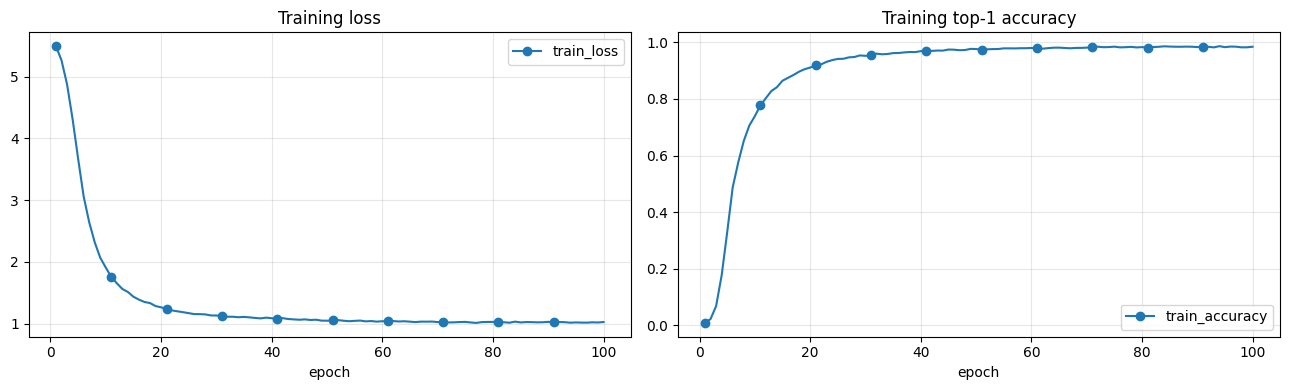

,epoch,train_loss,train_ce_loss,train_supcon_loss,train_policy_loss,train_reward,train_selector_entropy,train_selected_same_class_rate,train_accuracy,train_macro_f1,...,val_selected_same_class_rate,val_selector_entropy,best_val_loss,best_epoch,bad_epochs,backbone_trainable,backbone_lr,selector_lr,head_lr,fusion_mode
95,96,1.015556,1.046385,0.933032,-0.064784,0.120669,1.269693,0.531803,0.985142,0.984583,...,0.815385,1.270351,0.979320,94,2,True,1.126671e-07,5.363597e-07,5.363597e-07,tacs_gumbel_selector
96,97,1.014970,1.044094,0.908998,-0.061878,0.121195,1.269648,0.524804,0.984651,0.984170,...,0.817949,1.270351,0.979320,94,3,True,1.071298e-07,3.456090e-07,3.456090e-07,tacs_gumbel_selector
97,98,1.020045,1.046775,0.916818,-0.059874,0.122650,1.269666,0.532417,0.982318,0.981623,...,0.817949,1.270353,0.979320,94,4,True,1.031702e-07,2.092093e-07,2.092093e-07,tacs_gumbel_selector
98,99,1.017583,1.047275,0.959917,-0.064990,0.124876,1.269690,0.534995,0.982564,0.982218,...,0.817949,1.270350,0.979302,99,0,True,1.007928e-07,1.273098e-07,1.273098e-07,tacs_gumbel_selector
99,100,1.024569,1.047977,0.909795,-0.056202,0.124572,1.269674,0.529224,0.984528,0.983981,...,0.817949,1.270351,0.979302,99,1,True,1.000000e-07,1.000000e-07,1.000000e-07,tacs_gumbel_selector


In [27]:
import pandas as pd
if 'history_df' not in globals():
    history_df = pd.read_csv(OUT_PUT_DIR / 'training_history.csv')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
history_df.plot(x='epoch', y='train_loss', ax=axes[0], marker='o', markevery=max(1, len(history_df) // 10), title='Training loss')
history_df.plot(x='epoch', y='train_accuracy', ax=axes[1], marker='o', markevery=max(1, len(history_df) // 10), title='Training top-1 accuracy')
for axis in axes:
    axis.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
display(history_df.tail())


## 7. Official test accuracy

Cell này load best checkpoint, dùng selector TACS để chọn context tốt nhất từ toàn bộ candidate pool 20%, rồi in `test_accuracy`, tương ứng hàng **TACS (Ours)** cho Cars trong Table 2.


## 8. Inference và load checkpoint

Dùng hàm này để test nhanh một ảnh. Nếu không truyền context thủ công, selector TACS sẽ chọn context có utility score cao nhất từ candidate pool.


In [31]:
def macro_f1_score_np(y_true, y_pred, num_classes):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    f1_values = []
    for class_id in range(num_classes):
        tp = np.sum((y_true == class_id) & (y_pred == class_id))
        fp = np.sum((y_true != class_id) & (y_pred == class_id))
        fn = np.sum((y_true == class_id) & (y_pred != class_id))
        denom = 2 * tp + fp + fn
        f1_values.append(0.0 if denom == 0 else (2 * tp) / denom)
    return float(np.mean(f1_values))


def add_context_label_prior(logits, *args, **kwargs):
    return logits
@torch.no_grad()
def select_tacs_contexts_for_dataframe(query_embeddings, candidate_embeddings, query_df, candidate_df, network, top_k=1, exclude_self=False):
    scores = network.selector.score_full_pool(
        query_embeddings,
        candidate_embeddings,
        chunk_size=RETRIEVAL_CHUNK_SIZE,
        device=DEVICE,
    )
    if exclude_self:
        candidate_row_id_to_position = {int(row_id): pos for pos, row_id in enumerate(candidate_df['row_id'].tolist())}
        for query_index in range(len(query_df)):
            query_row_id = int(query_df.iloc[query_index]['row_id'])
            context_pos = candidate_row_id_to_position.get(query_row_id)
            if context_pos is not None and len(candidate_df) > 1:
                scores[query_index, context_pos] = -float('inf')
    values, positions = torch.topk(scores, k=min(top_k, len(candidate_df)), dim=1)
    return positions.numpy(), values.numpy()


def build_tacs_selected_pairs_df(query_df, candidate_df, context_positions, context_scores):
    context_positions = np.asarray(context_positions)
    context_scores = np.asarray(context_scores)
    if context_positions.ndim == 1:
        context_positions = context_positions[:, None]
        context_scores = context_scores[:, None]
    rows = []
    for query_pos, (positions_row, scores_row) in enumerate(zip(context_positions, context_scores)):
        query = query_df.iloc[query_pos]
        contexts = [candidate_df.iloc[int(pos)] for pos in positions_row]
        context_class_ids = [int(context['class_id']) for context in contexts]
        query_class_id = int(query['class_id'])
        rows.append({
            'query_fname': query['fname'],
            'query_class_id': query_class_id,
            'query_car_name': class_names[query_class_id],
            'top1_context_fname': contexts[0]['fname'],
            'top1_context_class_id': context_class_ids[0],
            'top1_context_car_name': class_names[context_class_ids[0]],
            'top1_context_pool_position': int(positions_row[0]),
            'top1_context_train_row_id': int(contexts[0]['row_id']),
            'top1_tacs_score': float(scores_row[0]),
            'context_fnames': '|'.join(str(context['fname']) for context in contexts),
            'context_class_ids': '|'.join(str(class_id) for class_id in context_class_ids),
            'context_pool_positions': '|'.join(str(int(pos)) for pos in positions_row),
            'tacs_scores': '|'.join(f'{float(score):.6f}' for score in scores_row),
            'same_class': bool(query_class_id == context_class_ids[0]),
            'same_class_top1': bool(query_class_id == context_class_ids[0]),
            'same_class_any_topk': bool(query_class_id in context_class_ids),
        })
    return pd.DataFrame(rows)


def make_selected_context_loader(query_df, query_embeddings, desc):
    context_positions, context_scores = select_tacs_contexts_for_dataframe(
        query_embeddings,
        candidate_selector_embeddings,
        query_df,
        candidate_df,
        model,
        top_k=CONTEXT_TOP_K,
        exclude_self=False,
    )
    pairs_df = build_tacs_selected_pairs_df(query_df, candidate_df, context_positions, context_scores)
    pairs_df.to_csv(OUT_PUT_DIR / f'{desc}_tacs_selected_context_pairs.csv', index=False)
    dataset = StanfordCarsSimilarityContextDataset(
        query_df,
        candidate_df,
        context_positions,
        context_scores,
        eval_transform,
        eval_transform,
        crop_bbox=USE_BBOX_CROP,
    )
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, **loader_kwargs)
    return loader, pairs_df


def move_context_batch_to_device(batch):
    return {
        'query_images': batch['query_image'].to(DEVICE, non_blocking=True),
        'context_images': batch['context_images'].to(DEVICE, non_blocking=True),
        'context_scores': batch['context_scores'].to(DEVICE, non_blocking=True),
        'context_labels': batch['context_labels'].to(DEVICE, non_blocking=True),
        'labels': batch['label'].to(DEVICE, non_blocking=True),
    }


@torch.no_grad()
def predict_logits_with_tta(network, query_images, context_images, context_scores, context_labels):
    logits_list = []
    logits = network(query_images, context_images, context_scores=context_scores)
    logits = add_context_label_prior(logits, context_labels, context_scores)
    logits_list.append(logits)
    if globals().get('EVAL_TTA_HORIZONTAL_FLIP', True):
        logits = network(
            torch.flip(query_images, dims=[-1]),
            torch.flip(context_images, dims=[-1]),
            context_scores=context_scores,
        )
        # logits = add_context_label_prior(logits, context_labels, context_scores)
        logits_list.append(logits)
    return torch.stack(logits_list, dim=0).mean(dim=0)


def evaluate_context_model(network, loader, selected_pairs_df, top_k=TOP_K):
    network.eval()
    total_loss = 0.0
    all_targets, all_predictions, rows = [], [], []
    top_k = min(top_k, NUM_CLASSES)
    with torch.inference_mode():
        for batch in tqdm(loader, desc='test', leave=False):
            moved = move_context_batch_to_device(batch)
            logits = predict_logits_with_tta(
                network,
                moved['query_images'],
                moved['context_images'],
                moved['context_scores'],
                moved['context_labels'],
            )
            loss = criterion(logits, moved['labels'])
            probs = torch.softmax(logits, dim=1).cpu()
            values, indices = torch.topk(probs, k=top_k, dim=1)
            predictions = logits.argmax(dim=1).detach().cpu()
            labels_cpu = moved['labels'].detach().cpu()
            context_labels_cpu = batch['context_labels'].cpu()
            context_scores_cpu = batch['context_scores'].cpu()
            total_loss += loss.item() * moved['query_images'].size(0)
            all_targets.extend(labels_cpu.tolist())
            all_predictions.extend(predictions.tolist())
            for row_index, (fname, ctx_fnames, label, pred, value_row, index_row) in enumerate(
                zip(batch['fname'], batch['context_fnames'], labels_cpu, predictions, values, indices)
            ):
                label_id = int(label)
                pred_id = int(pred)
                context_label_ids = [int(x) for x in context_labels_cpu[row_index].tolist()]
                context_score_values = [float(x) for x in context_scores_cpu[row_index].tolist()]
                top_class_ids = [int(index) for index in index_row]
                rows.append({
                    'fname': fname,
                    'true_class_id': label_id,
                    'true_car_name': class_names[label_id],
                    'context_fnames': ctx_fnames,
                    'context_class_ids': '|'.join(str(x) for x in context_label_ids),
                    'context_car_names': '|'.join(class_names[x] for x in context_label_ids),
                    'tacs_scores': '|'.join(f'{x:.6f}' for x in context_score_values),
                    'top1_context_fname': str(ctx_fnames).split('|')[0],
                    'top1_context_class_id': context_label_ids[0],
                    'top1_context_car_name': class_names[context_label_ids[0]],
                    'top1_tacs_score': context_score_values[0],
                    'same_class_context_top1': bool(label_id == context_label_ids[0]),
                    'same_class_context_any_topk': bool(label_id in context_label_ids),
                    'same_class_context': bool(label_id in context_label_ids),
                    'predicted_class_id': pred_id,
                    'predicted_car_name': class_names[pred_id],
                    'correct': bool(pred_id == label_id),
                    'confidence': float(value_row[0]),
                    'top_k_class_ids': '|'.join(str(index) for index in top_class_ids),
                    'top_k_car_names': '|'.join(class_names[index] for index in top_class_ids),
                    'top_k_probabilities': '|'.join(f'{float(value):.6f}' for value in value_row),
                })
    y_true = np.asarray(all_targets)
    y_pred = np.asarray(all_predictions)
    return {
        'test_loss': total_loss / len(loader.dataset),
        'test_accuracy': float(np.mean(y_true == y_pred)),
        'test_macro_f1': macro_f1_score_np(y_true, y_pred, NUM_CLASSES),
        'predictions': pd.DataFrame(rows),
    }


evaluation_checkpoint_path = best_checkpoint_path if best_checkpoint_path.is_file() else (
    checkpoint_path if checkpoint_path.is_file() else last_checkpoint_path
)
saved_checkpoint = torch.load(evaluation_checkpoint_path, map_location=DEVICE)
model.load_state_dict(saved_checkpoint['model_state_dict'])
model.eval()
print('Loaded checkpoint for evaluation:', evaluation_checkpoint_path.resolve())

test_selected_loader, test_selected_pairs_df = make_selected_context_loader(test_df, test_query_selector_embeddings, 'test')
results = evaluate_context_model(model, test_selected_loader, test_selected_pairs_df, top_k=TOP_K)
test_prediction_df = results.pop('predictions')
test_prediction_df.to_csv(OUT_PUT_DIR / 'test_predictions.csv', index=False)

metrics = {
    'method': 'TACS (Ours) - learned task-aligned context selection',
    'test_accuracy': results['test_accuracy'],
    'test_loss': results['test_loss'],
    'test_macro_f1': results['test_macro_f1'],
    'num_classes': NUM_CLASSES,
    'standard_train_size': len(full_train_df),
    'train_size': len(train_dataset),
    'val_size': len(val_dataset),
    'standard_test_size': len(test_selected_loader.dataset),
    'architecture': BACKBONE_NAME,
    'pretraining': 'DINOv3',
    'retriever': 'learned TACS selector over candidate pool',
    'fusion_mode': getattr(model, 'active_fusion_mode', saved_checkpoint.get('fusion_mode', 'unknown')),
    'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'seed': SEED,
    'use_bbox_crop': USE_BBOX_CROP,
    'candidate_pool_fraction': CANDIDATE_POOL_FRACTION,
    'candidate_pool_size': len(candidate_df),
    'context_top_k': CONTEXT_TOP_K,
    'tacs_candidates_per_query_train': TACS_CANDIDATES_PER_QUERY,
    'tacs_prefilter_top_similar_train': TACS_PREFILTER_TOP_SIMILAR,
    'tacs_gumbel_tau': TACS_GUMBEL_TAU,
    'tacs_policy_weight': TACS_POLICY_WEIGHT,
    'use_context_label_prior': USE_CONTEXT_LABEL_PRIOR,
    'test_context_top1_same_class_rate': float(test_prediction_df['same_class_context_top1'].mean()),
    'test_context_same_class_rate': float(test_prediction_df['same_class_context_any_topk'].mean()),
    'test_mean_top1_tacs_score': float(test_prediction_df['top1_tacs_score'].mean()),
    'checkpoint': str(evaluation_checkpoint_path),
    'checkpoint_selection': 'best_val_if_available',
}

with open(OUT_PUT_DIR / 'metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, ensure_ascii=False, indent=2)

print(f"test_accuracy: {metrics['test_accuracy']:.4f} ({metrics['test_accuracy'] * 100:.2f}%)")
print(f"test_loss: {metrics['test_loss']:.4f}")
print(f"test_macro_f1: {metrics['test_macro_f1']:.4f}")
print(f"top1_same_class_tacs_context_rate: {metrics['test_context_top1_same_class_rate']:.4f}")
print(f"any_top{CONTEXT_TOP_K}_same_class_tacs_context_rate: {metrics['test_context_same_class_rate']:.4f}")
print(f"mean_top1_tacs_score: {metrics['test_mean_top1_tacs_score']:.4f}")
print('Saved TACS selected pairs:', (OUT_PUT_DIR / 'test_tacs_selected_context_pairs.csv').resolve())
print('Saved test predictions:', (OUT_PUT_DIR / 'test_predictions.csv').resolve())
print('Saved metrics:', (OUT_PUT_DIR / 'metrics.json').resolve())
display(test_prediction_df.head())


Loaded checkpoint for evaluation: /kaggle/working/outputs/baseline_tacs_cars/best_val_checkpoint.pt


TACS full-pool selector:   0%|          | 0/2 [00:00<?, ?it/s]

test:   0%|          | 0/126 [00:00<?, ?it/s]

/tmp/ipykernel_2436/2912080412.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_2436/2912080412.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_2436/2912080412.py:74: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  "context_labels": torch.tensor(context_labels, dtype=torch.long),
/tmp/ipykernel_2436/2912080412.py:74: UserWarning: To copy construct from a tensor, it is reco

test_accuracy: 0.9498 (94.98%)
test_loss: 1.1246
test_macro_f1: 0.9490
top1_same_class_tacs_context_rate: 0.5170
any_top1_same_class_tacs_context_rate: 0.5170
mean_top1_tacs_score: 0.9750
Saved TACS selected pairs: /kaggle/working/outputs/baseline_tacs_cars/test_tacs_selected_context_pairs.csv
Saved test predictions: /kaggle/working/outputs/baseline_tacs_cars/test_predictions.csv
Saved metrics: /kaggle/working/outputs/baseline_tacs_cars/metrics.json


,fname,true_class_id,true_car_name,context_fnames,context_class_ids,context_car_names,tacs_scores,top1_context_fname,top1_context_class_id,top1_context_car_name,...,same_class_context_top1,same_class_context_any_topk,same_class_context,predicted_class_id,predicted_car_name,correct,confidence,top_k_class_ids,top_k_car_names,top_k_probabilities
0,00001.jpg,180,Suzuki Aerio Sedan 2007,04228.jpg,180,Suzuki Aerio Sedan 2007,0.969580,04228.jpg,180,Suzuki Aerio Sedan 2007,...,True,True,True,180,Suzuki Aerio Sedan 2007,True,0.948407,180|114|187|81|170,Suzuki Aerio Sedan 2007|Ford Focus Sedan 2007|...,0.948407|0.003896|0.003056|0.002028|0.001714
1,00002.jpg,102,Ferrari 458 Italia Convertible 2012,02057.jpg,101,Ferrari California Convertible 2012,0.991016,02057.jpg,101,Ferrari California Convertible 2012,...,False,False,False,102,Ferrari 458 Italia Convertible 2012,True,0.790774,102|103|101|100|134,Ferrari 458 Italia Convertible 2012|Ferrari 45...,0.790774|0.065232|0.037640|0.005467|0.005335
2,00003.jpg,144,Jeep Patriot SUV 2012,06909.jpg,146,Jeep Liberty SUV 2012,0.989837,06909.jpg,146,Jeep Liberty SUV 2012,...,False,False,False,144,Jeep Patriot SUV 2012,True,0.941100,144|146|153|145|69,Jeep Patriot SUV 2012|Jeep Liberty SUV 2012|La...,0.941100|0.007404|0.003717|0.001971|0.001826
3,00004.jpg,186,Toyota Camry Sedan 2012,00148.jpg,186,Toyota Camry Sedan 2012,0.993557,00148.jpg,186,Toyota Camry Sedan 2012,...,True,True,True,186,Toyota Camry Sedan 2012,True,0.935950,186|139|4|187|132,Toyota Camry Sedan 2012|Hyundai Azera Sedan 20...,0.935950|0.005637|0.004700|0.003654|0.001857
4,00005.jpg,184,Tesla Model S Sedan 2012,05420.jpg,184,Tesla Model S Sedan 2012,0.957012,05420.jpg,184,Tesla Model S Sedan 2012,...,True,True,True,184,Tesla Model S Sedan 2012,True,0.943332,184|104|172|193|166,Tesla Model S Sedan 2012|Fisker Karma Sedan 20...,0.943332|0.003571|0.002613|0.002305|0.001565


In [29]:
@torch.no_grad()
def find_tacs_contexts_for_image(image_path, top_k=CONTEXT_TOP_K):
    image_path = Path(image_path)
    selector_feature_backbone = load_dinov3_backbone().to(DEVICE).eval()
    image = eval_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.cuda.amp.autocast(enabled=DEVICE.type == 'cuda'):
        query_embedding = extract_cls_features(selector_feature_backbone, image)
    query_embedding = F.normalize(query_embedding.float(), dim=1).cpu()
    del selector_feature_backbone
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    scores = model.selector.score_full_pool(query_embedding, candidate_selector_embeddings, chunk_size=RETRIEVAL_CHUNK_SIZE, device=DEVICE)
    values, positions = torch.topk(scores, k=min(top_k, len(candidate_df)), dim=1)
    context_rows = [candidate_df.iloc[int(pos)] for pos in positions[0].tolist()]
    return context_rows, [float(score) for score in values[0].tolist()]
def load_tacs_model_for_inference(checkpoint_file, device=DEVICE):
    saved = torch.load(checkpoint_file, map_location=device)
    loaded_model = DinoV3TACSClassifier(
        repo_dir=DINOV3_REPO_DIR,
        model_name=DINOV3_MODEL_NAME,
        weights_path=resolve_dinov3_weights(),
        num_classes=len(saved['class_names']),
        feature_dim=FEATURE_DIM,
        allow_feature_fallback=False,
    )
    loaded_model.load_state_dict(saved['model_state_dict'])
    return loaded_model.to(device).eval(), saved['class_names']
model, class_names = load_tacs_model_for_inference(best_checkpoint_path)
def predict_one_image_with_tacs_context(image_path, context_image_paths=None, network=model, top_k=TOP_K):
    if network is None:
        network = model
    image_path = Path(image_path)
    if context_image_paths is None:
        context_rows, tacs_scores = find_tacs_contexts_for_image(image_path, top_k=CONTEXT_TOP_K)
        context_image_paths = [Path(row['image_path']) for row in context_rows]
        context_names = [class_names[int(row['class_id'])] for row in context_rows]
        context_labels = [int(row['class_id']) for row in context_rows]
    else:
        if isinstance(context_image_paths, (str, Path)):
            context_image_paths = [context_image_paths]
        context_image_paths = [Path(path) for path in context_image_paths]
        context_names = [None] * len(context_image_paths)
        context_labels = [0] * len(context_image_paths)
        tacs_scores = [0.0] * len(context_image_paths)

    query_image = eval_transform(Image.open(image_path).convert('RGB')).unsqueeze(0).to(DEVICE)
    context_images = torch.stack([eval_transform(Image.open(path).convert('RGB')) for path in context_image_paths], dim=0).unsqueeze(0).to(DEVICE)
    context_scores = torch.tensor([tacs_scores], dtype=torch.float32, device=DEVICE)
    context_labels_tensor = torch.tensor([context_labels], dtype=torch.long, device=DEVICE)

    network.eval()
    with torch.inference_mode():
        logits = predict_logits_with_tta(network, query_image, context_images, context_scores, context_labels_tensor)
        probs = torch.softmax(logits, dim=1)[0]
        values, indices = torch.topk(probs, k=min(top_k, NUM_CLASSES))

    print('Query:', image_path)
    for rank, (context_path, context_name, tacs_score) in enumerate(zip(context_image_paths, context_names, tacs_scores), start=1):
        print(f'TACS context {rank}:', context_path)
        if context_name is not None:
            print(f'  label: {context_name}')
        print(f'  TACS utility score: {tacs_score:.4f}')
    print('\nTop predictions:')
    for rank, (class_id, probability) in enumerate(zip(indices.tolist(), values.tolist()), start=1):
        print(f'{rank}. {class_names[class_id]} | p={probability:.4f}')





print('Final checkpoint:', checkpoint_path.resolve())
print('Best-val checkpoint:', best_checkpoint_path.resolve())
print('Latest checkpoint:', last_checkpoint_path.resolve())
print('Method:', 'TACS (Ours) - learned task-aligned context selection')


NameError: name 'load_tacs_model_for_inference' is not defined

In [10]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

## 9. Ghi chú benchmark

- Method này là bản **TACS (Ours)**: selector học chọn context theo downstream task, không phải frozen nearest-neighbor cố định.
- Candidate pool mặc định lấy **20% train split**, đúng phần Candidate Pool Construction trong paper.
- Training dùng straight-through Gumbel-Softmax (`TACS_GUMBEL_TAU=0.10`) cho `L_grad` và policy reward `loss_query_only - loss_with_context` cho `L_policy`.
- Để chạy được trên GPU thực tế, mỗi query train trên shortlist `TACS_CANDIDATES_PER_QUERY`; khi test, selector chọn từ toàn bộ candidate pool 20%.
- Notebook giữ các phần giúp bản tốt nhất đạt điểm cao: DINOv3 ViT-S/16, token-level fusion, gated query/context head, strong augmentation, BBox crop, checkpoint sau từng epoch và TTA.
- `USE_CONTEXT_LABEL_PRIOR=False` vì context-label prior không có trong TACS paper.
- Nếu bị OOM, giảm `BATCH_SIZE` xuống 32 hoặc `TACS_CANDIDATES_PER_QUERY` xuống 3.
- Metric chính cho Cars là `test_accuracy`; nên theo dõi thêm `top1_same_class_tacs_context_rate`, `train_reward`, `train_policy_loss`, và `selector_entropy`.
- Những file nên giữ để so sánh method: `metrics.json`, `training_history.csv`, `test_predictions.csv`, `candidate_pool.csv`, `tacs_selector_cache.pt`, `train_tacs_candidate_subsets.csv`, `test_tacs_selected_context_pairs.csv`, `checkpoint_last.pt`, `best_val_checkpoint.pt`, và final checkpoint.


In [ ]:

# --- CELL CUỐI: TỰ ĐỘNG DỪNG TÍNH TOÁN & SHUTDOWN PHIÊN ---
import os
import time
import torch

print("=== QUÁ TRÌNH HUẤN LUYỆN VÀ ĐÁNH GIÁ ĐÃ HOÀN TẤT ===")

# 1. Giải phóng toàn bộ VRAM
if torch.cuda.is_available():
    torch.cuda.empty_cache()

time.sleep(2)

# 2. Tắt Kernel để dừng ngay lập tức mọi tác vụ đang chạy
try:
    from ipykernel.kernelapp import IPKernelApp
    IPKernelApp.instance().shutdown()
except Exception:
    os._exit(0)

=== QUÁ TRÌNH HUẤN LUYỆN VÀ ĐÁNH GIÁ ĐÃ HOÀN TẤT ===


In [ ]:
# import numpy as np
# import pandas as pd
# from PIL import Image
# from tqdm import tqdm

# def analyze_dataset_dimensions(df, check_bbox=True):
#     widths, heights = [], []
#     crop_w_list, crop_h_list = [], []

#     for _, row in tqdm(df.iterrows(), total=len(df), desc="Đang quét kích thước ảnh"):
#         # Image.open chỉ đọc metadata header, cực nhanh và không tốn RAM
#         with Image.open(row['image_path']) as img:
#             w, h = img.size
#             widths.append(w)
#             heights.append(h)

#         if check_bbox and 'bbox_x1' in row:
#             left = max(0, int(row['bbox_x1']) - 1)
#             top = max(0, int(row['bbox_y1']) - 1)
#             right = max(left + 1, int(row['bbox_x2']))
#             bottom = max(top + 1, int(row['bbox_y2']))
#             crop_w_list.append(right - left)
#             crop_h_list.append(bottom - top)

#     data = {
#         "Metric": ["Min", "Max", "Mean", "Median"],
#         "Orig Width (W)": [np.min(widths), np.max(widths), round(np.mean(widths), 1), np.median(widths)],
#         "Orig Height (H)": [np.min(heights), np.max(heights), round(np.mean(heights), 1), np.median(heights)],
#     }

#     if check_bbox and crop_w_list:
#         data["Crop Width (BBox)"] = [np.min(crop_w_list), np.max(crop_w_list), round(np.mean(crop_w_list), 1), np.median(crop_w_list)]
#         data["Crop Height (BBox)"] = [np.min(crop_h_list), np.max(crop_h_list), round(np.mean(crop_h_list), 1), np.median(crop_h_list)]

#     stats_df = pd.DataFrame(data)
    
#     # Tính tỉ lệ khung hình (Aspect Ratio W/H)
#     aspect_ratios = np.array(widths) / np.array(heights)
#     print(f"Aspect ratio gốc trung bình (W/H): {aspect_ratios.mean():.2f}")
#     print(f"Số ảnh có W > H (ảnh ngang): {np.sum(aspect_ratios > 1.0)} / {len(df)} ({np.mean(aspect_ratios > 1.0):.1%})")
    
#     return stats_df

# # Kiểm tra trên tập train
# train_size_stats = analyze_dataset_dimensions(full_train_df, check_bbox=USE_BBOX_CROP)
# display(train_size_stats)